<a href="https://colab.research.google.com/github/Milu2662/BI-PYMES-ML/blob/main/notebook/04_isolation_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BI-PYMES-ML

In [22]:
!git clone https://github.com/Milu2662/BI-PYMES-ML.git /content/BI-PYMES-ML

fatal: destination path '/content/BI-PYMES-ML' already exists and is not an empty directory.


In [23]:
from pathlib import Path
import sys
candidates=[Path("/content/BI-PYMES-ML"),Path.cwd()]
PROJECT_DIR=next((p for p in candidates if (p/"src").exists()),Path.cwd())
if not (PROJECT_DIR/"src").exists():
    raise FileNotFoundError("No se encontró src/. Ajusta PROJECT_DIR a la raíz del repositorio.")
sys.path.insert(0,str(PROJECT_DIR))
for d in ["data/raw","data/processed","data/experimental","results/figures","results/metrics"]:
    (PROJECT_DIR/d).mkdir(parents=True,exist_ok=True)
print("Proyecto:",PROJECT_DIR)

Proyecto: /content/BI-PYMES-ML


In [25]:
from pathlib import Path
import shutil
import pandas as pd

# Definir rutas
DRIVE_DIR = Path("/content/drive/MyDrive/BI-PYMES-ML")
LOCAL_DIR = PROJECT_DIR / "data" / "processed"

source = DRIVE_DIR / "invoice_features.pkl"
destination = LOCAL_DIR / "invoice_features.pkl"

# Crear carpeta local
LOCAL_DIR.mkdir(parents=True, exist_ok=True)

# Verificar y copiar
assert source.exists(), f"No existe: {source}"

shutil.copy2(source, destination)

# Cargar archivo
invoice = pd.read_pickle(destination)

print("Origen:", source)
print("Destino:", destination)
print("Dimensiones:", invoice.shape)
print("Facturas únicas:", invoice["InvoiceNo"].nunique())
print("Columnas:", len(invoice.columns))

Origen: /content/drive/MyDrive/BI-PYMES-ML/invoice_features.pkl
Destino: /content/BI-PYMES-ML/data/processed/invoice_features.pkl
Dimensiones: (53628, 14)
Facturas únicas: 53628
Columnas: 14


In [26]:
from src.anomaly_detection import fit_isolation_forest

model, scored, features = fit_isolation_forest(
    invoice,
    contamination=0.03,
    random_state=42
)

print("MODELO ISOLATION FOREST BASE")
print("-" * 45)
print("Facturas evaluadas:", len(scored))
print("Variables utilizadas:", features)
print("Anomalías:", int(scored["if_anomaly"].sum()))
print(
    "Porcentaje:",
    round(scored["if_anomaly"].mean() * 100, 3),
    "%"
)

MODELO ISOLATION FOREST BASE
---------------------------------------------
Facturas evaluadas: 53628
Variables utilizadas: ['line_count', 'total_quantity', 'mean_quantity', 'mean_unit_price', 'total_revenue', 'revenue_abs', 'min_unit_price', 'max_unit_price', 'cancellation_line_share']
Anomalías: 1609
Porcentaje: 3.0 %


In [27]:
import pandas as pd
import numpy as np
from pathlib import Path

# 1. CARGAR DATOS TRANSACCIONALES
raw_path = Path(
    "/content/drive/MyDrive/BI-PYMES-ML/retail_lines.pkl"
)

df_raw = pd.read_pickle(raw_path).copy()

df_raw["InvoiceNo"] = (
    df_raw["InvoiceNo"].astype("string").str.strip()
)

df_raw["StockCode_norm"] = (
    df_raw["StockCode"].astype("string")
    .str.strip()
    .str.upper()
)

# 2. CLASIFICAR CÓDIGOS ESPECIALES

special_categories = {
    "POST": "POSTAGE",
    "DOT": "POSTAGE",
    "M": "MANUAL_ADJUSTMENT",
    "C2": "CARRIAGE",
    "D": "DISCOUNT",
    "S": "SAMPLES",
    "BANK CHARGES": "BANK_CHARGE",
    "ADJUST": "ACCOUNTING_ADJUSTMENT",
    "ADJUST2": "ACCOUNTING_ADJUSTMENT",
    "AMAZONFEE": "PLATFORM_FEE",
    "CRUK": "COMMISSION",
    "B": "BAD_DEBT_ADJUSTMENT"
}

df_raw["transaction_category"] = (
    df_raw["StockCode_norm"]
    .map(special_categories)
    .fillna("STANDARD_PRODUCT")
)

# 3. CONSTRUIR COMPOSICIÓN POR FACTURA

invoice_composition = pd.crosstab(
    df_raw["InvoiceNo"],
    df_raw["transaction_category"]
)

invoice_composition["total_lines"] = (
    invoice_composition.sum(axis=1)
)

invoice_composition["special_line_share"] = (
    1 - (
        invoice_composition["STANDARD_PRODUCT"]
        / invoice_composition["total_lines"]
    )
)

# 4. CLASIFICAR TIPO DE FACTURA

special_cols = [
    col for col in invoice_composition.columns
    if col not in [
        "STANDARD_PRODUCT",
        "total_lines",
        "special_line_share"
    ]
]

has_standard = (
    invoice_composition["STANDARD_PRODUCT"] > 0
)

has_special = (
    invoice_composition[special_cols].sum(axis=1) > 0
)

invoice_composition["invoice_type"] = np.select(
    [
        has_standard & has_special,
        ~has_standard & has_special
    ],
    [
        "MIXED",
        "SPECIAL_ONLY"
    ],
    default="STANDARD_ONLY"
)

# 5. CALCULAR PROPORCIONES

category_cols = [
    col for col in invoice_composition.columns
    if col not in [
        "total_lines",
        "special_line_share",
        "invoice_type"
    ]
]

for col in category_cols:
    invoice_composition[f"share_{col}"] = (
        invoice_composition[col]
        / invoice_composition["total_lines"]
    )

# 6. INTEGRAR CON LAS 14 VARIABLES ORIGINALES

invoice_enriched = invoice.copy()

invoice_enriched = invoice_enriched.merge(
    invoice_composition[
        ["special_line_share", "invoice_type"]
        + [f"share_{col}" for col in category_cols]
    ].reset_index(),
    on="InvoiceNo",
    how="left",
    validate="one_to_one"
)

print("Dimensiones:", invoice_enriched.shape)
print("Facturas:", invoice_enriched["InvoiceNo"].nunique())
print("Duplicados:", invoice_enriched["InvoiceNo"].duplicated().sum())

print("\nDistribución por composición:")
display(invoice_enriched["invoice_type"].value_counts())

Dimensiones: (53628, 27)
Facturas: 53628
Duplicados: 0

Distribución por composición:


,count
invoice_type,
STANDARD_ONLY,48203
MIXED,3994
SPECIAL_ONLY,1431


In [28]:
from pathlib import Path
import shutil

# Rutas
local_dir = PROJECT_DIR / "data" / "processed"
drive_dir = Path("/content/drive/MyDrive/BI-PYMES-ML")

local_dir.mkdir(parents=True, exist_ok=True)
drive_dir.mkdir(parents=True, exist_ok=True)

# Archivos locales
local_pkl = local_dir / "invoice_features_enriched.pkl"
local_csv = local_dir / "invoice_features_enriched.csv"

# Guardar localmente
invoice_enriched.to_pickle(local_pkl)
invoice_enriched.to_csv(local_csv, index=False)

# Copiar a Google Drive
drive_pkl = drive_dir / "invoice_features_enriched.pkl"
drive_csv = drive_dir / "invoice_features_enriched.csv"

shutil.copy2(local_pkl, drive_pkl)
shutil.copy2(local_csv, drive_csv)

print("ARCHIVOS GUARDADOS CORRECTAMENTE")
print("PKL:", drive_pkl)
print("CSV:", drive_csv)
print("Dimensiones:", invoice_enriched.shape)

ARCHIVOS GUARDADOS CORRECTAMENTE
PKL: /content/drive/MyDrive/BI-PYMES-ML/invoice_features_enriched.pkl
CSV: /content/drive/MyDrive/BI-PYMES-ML/invoice_features_enriched.csv
Dimensiones: (53628, 27)


## 4. Isolation Forest
El parámetro `contamination` representa una fracción esperada configurada para el algoritmo; no es una medición conocida de errores reales.

In [29]:
from src.anomaly_detection import fit_isolation_forest

# Variables enriquecidas
enriched_features = [
    "line_count",
    "total_quantity",
    "mean_quantity",
    "mean_unit_price",
    "total_revenue",
    "revenue_abs",
    "min_unit_price",
    "max_unit_price",
    "cancellation_line_share",
    "special_line_share",
    "share_STANDARD_PRODUCT",
    "share_POSTAGE",
    "share_MANUAL_ADJUSTMENT",
    "share_DISCOUNT",
    "share_BANK_CHARGE",
    "share_PLATFORM_FEE"
]

model_enriched, scored_enriched, used_features_enriched = (
    fit_isolation_forest(
        invoice_enriched,
        contamination=0.03,
        random_state=42,
        feature_cols=enriched_features
    )
)

print("ISOLATION FOREST ENRIQUECIDO")
print("-" * 50)
print("Facturas:", len(scored_enriched))
print("Variables:", len(used_features_enriched))
print("Anomalías:", int(scored_enriched["if_anomaly"].sum()))
print(
    "Porcentaje:",
    round(scored_enriched["if_anomaly"].mean() * 100, 3),
    "%"
)

ISOLATION FOREST ENRIQUECIDO
--------------------------------------------------
Facturas: 53628
Variables: 16
Anomalías: 1609
Porcentaje: 3.0 %


In [43]:
import joblib
from pathlib import Path

# Directorio de resultados
output_dir = PROJECT_DIR / "results" / "metrics"
output_dir.mkdir(parents=True, exist_ok=True)

# Guardar resultados del modelo base
base_results = scored.copy()

base_results.to_csv(
    output_dir / "isolation_forest_base_scores.csv",
    index=False
)

joblib.dump(
    model,
    output_dir / "isolation_forest_base_model.joblib"
)

# Guardar resultados del modelo enriquecido
enriched_results = scored_enriched.copy()

enriched_results.to_csv(
    output_dir / "isolation_forest_enriched_scores.csv",
    index=False
)

joblib.dump(
    model_enriched,
    output_dir / "isolation_forest_enriched_model.joblib"
)

print("Resultados guardados correctamente.")
print("Modelo base:", len(base_results), "facturas")
print("Modelo enriquecido:", len(enriched_results), "facturas")

Resultados guardados correctamente.
Modelo base: 53628 facturas
Modelo enriquecido: 53628 facturas


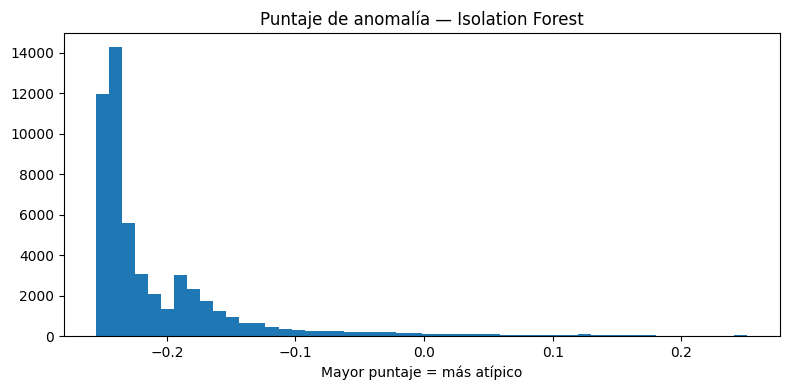

In [31]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4)); plt.hist(scored.if_score,bins=50)
plt.title("Puntaje de anomalía — Isolation Forest")
plt.xlabel("Mayor puntaje = más atípico"); plt.tight_layout()
plt.savefig(PROJECT_DIR/"results/figures/isolation_forest_scores.png",dpi=160); plt.show()

In [32]:
import pandas as pd
import numpy as np

# AUDITORÍA DE RESULTADOS ISOLATION FOREST

results = scored.copy()

# Identificar facturas de cancelación
results["is_cancellation_invoice"] = (
    results["InvoiceNo"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.startswith("C")
)
# Separar anomalías y registros normales
anomalies = results[results["if_anomaly"] == 1].copy()
normal = results[results["if_anomaly"] == 0].copy()

print("AUDITORÍA DE ISOLATION FOREST")

# 1. Resumen general
print("\n1. RESUMEN GENERAL")

print("Total facturas:", len(results))
print("Anomalías detectadas:", len(anomalies))
print("Registros normales:", len(normal))

# 2. Cancelaciones dentro de las anomalías
print("\n2. CANCELACIONES ENTRE LAS ANOMALÍAS")

display(
    pd.crosstab(
        anomalies["is_cancellation_invoice"],
        columns="Cantidad"
    )
)

# 3. Porcentaje de cancelaciones
cancellation_rate = (
    anomalies["is_cancellation_invoice"].mean() * 100
)

print(
    "Porcentaje de cancelaciones entre anomalías:",
    round(cancellation_rate, 2), "%"
)

# 4. Comparar anomalías y registros normales
print("\n3. COMPARACIÓN DE GRUPOS")

comparison = results.groupby("if_anomaly").agg(
    invoices=("InvoiceNo", "count"),
    cancellation_share=("is_cancellation_invoice", "mean"),
    mean_revenue=("total_revenue", "mean"),
    median_revenue=("total_revenue", "median"),
    mean_quantity=("total_quantity", "mean"),
    mean_unit_price=("mean_unit_price", "mean"),
    mean_lines=("line_count", "mean")
)

comparison.index = ["Normales", "Anómalas"]

display(comparison.round(4))

# 5. Anomalías que NO son cancelaciones
print("\n4. ANOMALÍAS SIN PREFIJO DE CANCELACIÓN")

non_cancellation_anomalies = anomalies[
    ~anomalies["is_cancellation_invoice"]
]

print("Cantidad:", len(non_cancellation_anomalies))

display(
    non_cancellation_anomalies.sort_values(
        "if_score", ascending=False
    ).head(20)
)

# 6. Guardar auditoría
output_dir = PROJECT_DIR / "results/metrics"

comparison.to_csv(
    output_dir / "isolation_forest_comparison.csv"
)

non_cancellation_anomalies.to_csv(
    output_dir / "isolation_forest_non_cancellations.csv",
    index=False
)

print("\nAuditoría guardada correctamente.")

AUDITORÍA DE ISOLATION FOREST

1. RESUMEN GENERAL
Total facturas: 53628
Anomalías detectadas: 1609
Registros normales: 52019

2. CANCELACIONES ENTRE LAS ANOMALÍAS


col_0,Cantidad
is_cancellation_invoice,
False,1078
True,531


Porcentaje de cancelaciones entre anomalías: 33.0 %

3. COMPARACIÓN DE GRUPOS


,invoices,cancellation_share,mean_revenue,median_revenue,mean_quantity,mean_unit_price,mean_lines
Normales,52019,0.1492,290.7946,192.34,158.8509,0.7481,17.4240
Anómalas,1609,0.3300,2585.7089,1934.53,1457.5674,671.9160,100.0559



4. ANOMALÍAS SIN PREFIJO DE CANCELACIÓN
Cantidad: 1078


,InvoiceNo,line_count,total_quantity,mean_quantity,mean_unit_price,total_revenue,revenue_abs,min_unit_price,max_unit_price,cancellation_line_share,invoice_date,customer_id,country,invoice_month,if_label,if_anomaly,if_score,is_cancellation_invoice
23921,537632,2,2,1.000000,13541.330000,27082.66,27082.66,13541.33,13541.33,0.0,2010-12-07 15:08:00,NaN,United Kingdom,2010-12,-1,1,0.246248,False
11724,512771,1,1,1.000000,25111.090000,25111.09,25111.09,25111.09,25111.09,0.0,2010-06-17 16:53:00,NaN,United Kingdom,2010-06,-1,1,0.246063,False
16579,522796,1,1,1.000000,10468.800000,10468.80,10468.80,10468.80,10468.80,0.0,2010-09-16 15:12:00,NaN,United Kingdom,2010-09,-1,1,0.243660,False
17971,525399,1,1,1.000000,10468.800000,10468.80,10468.80,10468.80,10468.80,0.0,2010-10-05 11:49:00,NaN,United Kingdom,2010-10,-1,1,0.243660,False
45333,A563185,1,1,1.000000,11062.060000,11062.06,11062.06,11062.06,11062.06,0.0,2011-08-12 14:50:00,NaN,United Kingdom,2011-08,-1,1,0.243660,False
17326,524159,1,1,1.000000,10468.800000,10468.80,10468.80,10468.80,10468.80,0.0,2010-09-27 16:12:00,14063.0,United Kingdom,2010-09,-1,1,0.243660,False
6390,502263,1,1,1.000000,10953.500000,10953.50,10953.50,10953.50,10953.50,0.0,2010-03-23 15:22:00,12918.0,United Kingdom,2010-03,-1,1,0.243660,False
6391,502265,1,1,1.000000,10953.500000,10953.50,10953.50,10953.50,10953.50,0.0,2010-03-23 15:28:00,NaN,United Kingdom,2010-03,-1,1,0.243660,False
3167,496115,1,1,1.000000,8985.600000,8985.60,8985.60,8985.60,8985.60,0.0,2010-01-29 11:04:00,17949.0,United Kingdom,2010-01,-1,1,0.236677,False
30634,551697,1,1,1.000000,8142.750000,8142.75,8142.75,8142.75,8142.75,0.0,2011-05-03 13:46:00,16029.0,United Kingdom,2011-05,-1,1,0.233937,False



Auditoría guardada correctamente.


In [33]:
import pandas as pd
import numpy as np

# Cargar registros originales
raw_path = "/content/drive/MyDrive/BI-PYMES-ML/retail_lines.pkl"
df_raw = pd.read_pickle(raw_path)

# Facturas que queremos investigar
ids = [
    "537632",
    "512771",
    "522796",
    "525399",
    "A563185",
    "573585"
]

df_raw["InvoiceNo"] = df_raw["InvoiceNo"].astype(str).str.strip()

# Extraer transacciones originales
sample = df_raw[df_raw["InvoiceNo"].isin(ids)].copy()

# Recalcular características
audit = sample.groupby("InvoiceNo").agg(
    original_lines=("InvoiceNo", "size"),
    original_quantity=("Quantity", "sum"),
    original_revenue=("Revenue", "sum"),
    average_price=("UnitPrice", "mean"),
    minimum_price=("UnitPrice", "min"),
    maximum_price=("UnitPrice", "max"),
    distinct_products=("StockCode", "nunique")
).reset_index()

# Mostrar resultados
print("AUDITORÍA DE FACTURAS EXTREMAS")
display(audit)

# Investigar códigos de producto especiales
print("CÓDIGOS DE PRODUCTO EN LAS FACTURAS")
display(
    sample.groupby(["InvoiceNo", "StockCode"])
    .agg(
        lines=("StockCode", "size"),
        quantity=("Quantity", "sum"),
        unit_price=("UnitPrice", "mean")
    )
    .reset_index()
)

AUDITORÍA DE FACTURAS EXTREMAS


,InvoiceNo,original_lines,original_quantity,original_revenue,average_price,minimum_price,maximum_price,distinct_products
0,512771,1,1,25111.09,25111.090000,25111.09,25111.09,1
1,522796,1,1,10468.80,10468.800000,10468.80,10468.80,1
2,525399,1,1,10468.80,10468.800000,10468.80,10468.80,1
3,537632,2,2,27082.66,13541.330000,13541.33,13541.33,1
4,573585,1114,5198,16874.58,6.311813,0.42,2019.05,1110
5,A563185,1,1,11062.06,11062.060000,11062.06,11062.06,1


CÓDIGOS DE PRODUCTO EN LAS FACTURAS


,InvoiceNo,StockCode,lines,quantity,unit_price
0,512771,M,1,1,25111.09
1,522796,M,1,1,10468.80
2,525399,M,1,1,10468.80
3,537632,AMAZONFEE,2,2,13541.33
4,573585,11001,1,2,3.29
...,...,...,...,...,...
1110,573585,90209C,1,3,2.07
1111,573585,90214S,1,1,0.83
1112,573585,DOT,1,1,2019.05
1113,573585,gift_0001_20,1,1,16.67


In [34]:
# AUDITORÍA DE CÓDIGOS DE PRODUCTO ESPECIALES

import pandas as pd
import numpy as np

# Cargar datos originales
raw_path = "/content/drive/MyDrive/BI-PYMES-ML/retail_lines.pkl"
df_raw = pd.read_pickle(raw_path)

df_raw["StockCode"] = df_raw["StockCode"].astype(str).str.strip()

# Identificar códigos con precios unitarios extremos
product_audit = (
    df_raw.groupby("StockCode")
    .agg(
        transaction_lines=("StockCode", "size"),
        distinct_invoices=("InvoiceNo", "nunique"),
        mean_price=("UnitPrice", "mean"),
        median_price=("UnitPrice", "median"),
        max_price=("UnitPrice", "max"),
        min_price=("UnitPrice", "min"),
        total_revenue=("Revenue", "sum")
    )
    .reset_index()
)

# Ordenar por precio máximo
display(
    product_audit
    .sort_values("max_price", ascending=False)
    .head(30)
)

# Revisar códigos especiales identificados
special_codes = ["M", "B", "AMAZONFEE", "DOT"]

display(
    product_audit[
        product_audit["StockCode"].isin(special_codes)
    ].sort_values("max_price", ascending=False)
)

,StockCode,transaction_lines,distinct_invoices,mean_price,median_price,max_price,min_price,total_revenue
5287,M,1421,1286,528.776284,12.680,38970.00,0.000,-82796.320
5246,BANK CHARGES,102,95,359.034422,42.120,18910.69,0.001,-35562.629
5244,AMAZONFEE,43,36,7646.089302,6497.470,17836.46,1.000,-260763.580
5245,B,6,6,-24602.346667,-24993.965,11062.06,-53594.360,-147614.080
5289,POST,2122,2084,32.623322,18.000,8142.75,0.000,112341.000
5242,ADJUST,67,67,163.591343,49.350,5117.03,4.570,6835.240
5285,DOT,1446,1425,223.144876,154.180,4505.17,0.000,322647.470
5250,D,177,151,72.867288,19.000,1867.86,0.010,-13484.540
3785,84016,78,72,42.633974,0.420,1157.15,0.000,3741.370
5249,CRUK,16,16,495.839375,471.770,1100.44,1.600,-7933.430


,StockCode,transaction_lines,distinct_invoices,mean_price,median_price,max_price,min_price,total_revenue
5287,M,1421,1286,528.776284,12.680,38970.00,0.00,-82796.32
5244,AMAZONFEE,43,36,7646.089302,6497.470,17836.46,1.00,-260763.58
5245,B,6,6,-24602.346667,-24993.965,11062.06,-53594.36,-147614.08
5285,DOT,1446,1425,223.144876,154.180,4505.17,0.00,322647.47


In [35]:
# INVESTIGACIÓN DE DESCRIPCIONES ESPECIALES
import pandas as pd

special_codes = [
    "M", "B", "BANK CHARGES", "AMAZONFEE",
    "POST", "ADJUST", "ADJUST2", "DOT",
    "D", "CRUK", "C2", "S"
]

description_audit = (
    df_raw[
        df_raw["StockCode"].astype(str).str.strip().isin(special_codes)
    ]
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        transaction_lines=("InvoiceNo", "size"),
        distinct_invoices=("InvoiceNo", "nunique"),
        mean_price=("UnitPrice", "mean"),
        max_price=("UnitPrice", "max"),
        min_price=("UnitPrice", "min"),
        total_revenue=("Revenue", "sum")
    )
    .reset_index()
    .sort_values(["StockCode", "transaction_lines"],
                 ascending=[True, False])
)

display(description_audit)

,StockCode,Description,transaction_lines,distinct_invoices,mean_price,max_price,min_price,total_revenue
1,ADJUST,Adjustment by john on 26/01/2010 16,38,38,75.408684,342.80,4.570,1803.330
2,ADJUST,Adjustment by john on 26/01/2010 17,26,26,283.232308,5117.03,10.510,5762.960
0,ADJUST,Adjustment by Peter on 24/05/2010 1,3,3,243.683333,358.47,72.450,-731.050
3,ADJUST2,Adjustment by Peter on Jun 25 2010,3,3,243.683333,358.47,72.450,731.050
4,AMAZONFEE,AMAZON FEE,43,36,7646.089302,17836.46,1.000,-260763.580
5,B,Adjust bad debt,6,6,-24602.346667,11062.06,-53594.360,-147614.080
7,BANK CHARGES,Bank Charges,96,89,359.297406,18910.69,0.001,-33493.669
6,BANK CHARGES,Bank Charges,6,6,354.826667,848.43,15.000,-2068.960
8,C2,CARRIAGE,279,274,49.992832,150.00,15.000,13386.000
9,C2,NaN,3,3,0.000000,0.00,0.000,0.000


In [36]:
# CLASIFICACIÓN DE CÓDIGOS DE PRODUCTO

import numpy as np
import pandas as pd

# Normalizar códigos
df_raw["StockCode"] = (
    df_raw["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Clasificación de códigos especiales
special_categories = {
    "M": "MANUAL_ADJUSTMENT",
    "B": "BAD_DEBT_ADJUSTMENT",
    "BANK CHARGES": "BANK_CHARGE",
    "AMAZONFEE": "PLATFORM_FEE",
    "ADJUST": "ACCOUNTING_ADJUSTMENT",
    "ADJUST2": "ACCOUNTING_ADJUSTMENT",
    "C2": "CARRIAGE",
    "CRUK": "COMMISSION",
    "D": "DISCOUNT",
    "DOT": "POSTAGE",
    "POST": "POSTAGE",
    "S": "SAMPLES"
}

df_raw["transaction_category"] = (
    df_raw["StockCode"]
    .map(special_categories)
    .fillna("STANDARD_PRODUCT")
)

# Resumen de categorías
category_summary = (
    df_raw.groupby("transaction_category")
    .agg(
        transaction_lines=("InvoiceNo", "size"),
        distinct_invoices=("InvoiceNo", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_revenue=("Revenue", "sum"),
        mean_unit_price=("UnitPrice", "mean")
    )
    .reset_index()
    .sort_values("transaction_lines", ascending=False)
)

display(category_summary)

# Distribución porcentual
category_summary["line_percentage"] = (
    category_summary["transaction_lines"]
    / len(df_raw) * 100
)

display(category_summary)

,transaction_category,transaction_lines,distinct_invoices,total_quantity,total_revenue,mean_unit_price
10,STANDARD_PRODUCT,1061577,52197,10593167,1.938552e+07,3.342878
8,POSTAGE,3568,3506,13046,4.349885e+05,109.835813
6,MANUAL_ADJUSTMENT,1426,1290,4612,-8.278127e+04,526.932784
3,CARRIAGE,282,277,716,1.338600e+04,49.460993
5,DISCOUNT,177,151,-2872,-1.348454e+04,72.867288
9,SAMPLES,104,37,-98,-6.065800e+03,60.956731
2,BANK_CHARGE,102,95,-42,-3.556263e+04,359.034422
0,ACCOUNTING_ADJUSTMENT,70,70,8,7.566290e+03,167.023857
7,PLATFORM_FEE,43,36,-35,-2.607636e+05,7646.089302
4,COMMISSION,16,16,-16,-7.933430e+03,495.839375


,transaction_category,transaction_lines,distinct_invoices,total_quantity,total_revenue,mean_unit_price,line_percentage
10,STANDARD_PRODUCT,1061577,52197,10593167,1.938552e+07,3.342878,99.457171
8,POSTAGE,3568,3506,13046,4.349885e+05,109.835813,0.334279
6,MANUAL_ADJUSTMENT,1426,1290,4612,-8.278127e+04,526.932784,0.133599
3,CARRIAGE,282,277,716,1.338600e+04,49.460993,0.026420
5,DISCOUNT,177,151,-2872,-1.348454e+04,72.867288,0.016583
9,SAMPLES,104,37,-98,-6.065800e+03,60.956731,0.009744
2,BANK_CHARGE,102,95,-42,-3.556263e+04,359.034422,0.009556
0,ACCOUNTING_ADJUSTMENT,70,70,8,7.566290e+03,167.023857,0.006558
7,PLATFORM_FEE,43,36,-35,-2.607636e+05,7646.089302,0.004029
4,COMMISSION,16,16,-16,-7.933430e+03,495.839375,0.001499


In [37]:
# CARACTERÍSTICAS DE FACTURAS CON CATEGORÍAS
invoice = (
    df_raw.groupby("InvoiceNo")
    .agg(
        line_count=("InvoiceNo", "size"),
        total_quantity=("Quantity", "sum"),
        mean_quantity=("Quantity", "mean"),
        mean_unit_price=("UnitPrice", "mean"),
        total_revenue=("Revenue", "sum"),
        revenue_abs=("Revenue", lambda x: x.abs().sum()),
        min_unit_price=("UnitPrice", "min"),
        max_unit_price=("UnitPrice", "max"),
        cancellation_line_share=(
            "InvoiceNo",
            lambda x: 0
        ),
        special_line_share=(
            "transaction_category",
            lambda x: (x != "STANDARD_PRODUCT").mean()
        ),
        invoice_date=("InvoiceDate", "min"),
        customer_id=("CustomerID", "first"),
        country=("Country", "first")
    )
    .reset_index()
)

# Identificar facturas canceladas por prefijo C
invoice["is_cancellation"] = (
    invoice["InvoiceNo"].astype(str).str.startswith("C")
).astype(int)

# Recuperar el porcentaje de líneas canceladas por factura
cancellation_share = (
    df_raw.assign(
        is_cancelled_line=(
            df_raw["InvoiceNo"].astype(str).str.startswith("C")
        )
    )
    .groupby("InvoiceNo")["is_cancelled_line"]
    .mean()
)

invoice["cancellation_line_share"] = (
    invoice["InvoiceNo"].map(cancellation_share)
)

# Mes de facturación
invoice["invoice_month"] = (
    invoice["invoice_date"].dt.to_period("M").astype(str)
)

display(invoice.head())
print("Dimensiones:", invoice.shape)

,InvoiceNo,line_count,total_quantity,mean_quantity,mean_unit_price,total_revenue,revenue_abs,min_unit_price,max_unit_price,cancellation_line_share,special_line_share,invoice_date,customer_id,country,is_cancellation,invoice_month
0,489434,8,166,20.750000,4.081250,505.30,505.30,1.25,6.95,0.0,0.0,2009-12-01 07:45:00,13085.0,United Kingdom,0,2009-12
1,489435,4,60,15.000000,2.625000,145.80,145.80,1.65,3.75,0.0,0.0,2009-12-01 07:46:00,13085.0,United Kingdom,0,2009-12
2,489436,19,193,10.157895,3.730526,630.33,630.33,1.25,8.50,0.0,0.0,2009-12-01 09:06:00,13078.0,United Kingdom,0,2009-12
3,489437,23,145,6.304348,3.628261,310.75,310.75,0.65,9.95,0.0,0.0,2009-12-01 09:08:00,15362.0,United Kingdom,0,2009-12
4,489438,17,826,48.588235,2.591176,2286.24,2286.24,0.98,6.40,0.0,0.0,2009-12-01 09:24:00,18102.0,United Kingdom,0,2009-12


Dimensiones: (53628, 16)


In [38]:
# AUDITORÍA DE COMPOSICIÓN DE FACTURAS

invoice_composition = (
    df_raw.groupby("InvoiceNo")
    .agg(
        total_lines=("InvoiceNo", "size"),
        special_lines=(
            "transaction_category",
            lambda x: (x != "STANDARD_PRODUCT").sum()
        ),
        standard_lines=(
            "transaction_category",
            lambda x: (x == "STANDARD_PRODUCT").sum()
        ),
        distinct_categories=("transaction_category", "nunique")
    )
    .reset_index()
)

invoice_composition["special_line_share"] = (
    invoice_composition["special_lines"]
    / invoice_composition["total_lines"]
)

invoice_composition["invoice_type"] = np.select(
    [
        invoice_composition["special_lines"] == 0,
        invoice_composition["standard_lines"] == 0
    ],
    [
        "STANDARD_ONLY",
        "SPECIAL_ONLY"
    ],
    default="MIXED"
)

display(
    invoice_composition["invoice_type"]
    .value_counts()
    .rename_axis("invoice_type")
    .reset_index(name="invoice_count")
)

display(
    invoice_composition.sort_values(
        "special_line_share",
        ascending=False
    ).head(15)
)

,invoice_type,invoice_count
0,STANDARD_ONLY,48203
1,MIXED,3994
2,SPECIAL_ONLY,1431


,InvoiceNo,total_lines,special_lines,standard_lines,distinct_categories,special_line_share,invoice_type
51354,C554002,1,1,0,1,1.0,SPECIAL_ONLY
11373,512044,1,1,0,1,1.0,SPECIAL_ONLY
11369,512029,1,1,0,1,1.0,SPECIAL_ONLY
11368,512024,1,1,0,1,1.0,SPECIAL_ONLY
11367,512011,1,1,0,1,1.0,SPECIAL_ONLY
11365,512002,1,1,0,1,1.0,SPECIAL_ONLY
11362,511997,1,1,0,1,1.0,SPECIAL_ONLY
11354,511988,1,1,0,1,1.0,SPECIAL_ONLY
19359,528168,1,1,0,1,1.0,SPECIAL_ONLY
51335,C553841,1,1,0,1,1.0,SPECIAL_ONLY


In [39]:
# CARACTERÍSTICAS ADICIONALES POR FACTURA

category_shares = (
    pd.crosstab(
        df_raw["InvoiceNo"],
        df_raw["transaction_category"],
        normalize="index"
    )
    .add_prefix("share_")
    .reset_index()
)

invoice = invoice.merge(
    category_shares,
    on="InvoiceNo",
    how="left",
    validate="one_to_one"
)

print("Dimensiones actualizadas:", invoice.shape)

display(invoice.head())

Dimensiones actualizadas: (53628, 27)


,InvoiceNo,line_count,total_quantity,mean_quantity,mean_unit_price,total_revenue,revenue_abs,min_unit_price,max_unit_price,cancellation_line_share,...,share_BAD_DEBT_ADJUSTMENT,share_BANK_CHARGE,share_CARRIAGE,share_COMMISSION,share_DISCOUNT,share_MANUAL_ADJUSTMENT,share_PLATFORM_FEE,share_POSTAGE,share_SAMPLES,share_STANDARD_PRODUCT
0,489434,8,166,20.750000,4.081250,505.30,505.30,1.25,6.95,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,489435,4,60,15.000000,2.625000,145.80,145.80,1.65,3.75,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,489436,19,193,10.157895,3.730526,630.33,630.33,1.25,8.50,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,489437,23,145,6.304348,3.628261,310.75,310.75,0.65,9.95,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,489438,17,826,48.588235,2.591176,2286.24,2286.24,0.98,6.40,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [40]:
# AUDITORÍA CRUZADA: TIPO DE FACTURA Y CANCELACIONES

# Construir tabla de auditoría sin duplicar columnas
invoice_audit = invoice.merge(
    invoice_composition[
        ["InvoiceNo", "invoice_type"]
    ],
    on="InvoiceNo",
    how="left",
    validate="one_to_one"
)

# Verificar integridad
assert len(invoice_audit) == len(invoice)
assert invoice_audit["invoice_type"].notna().all()

# 1. Frecuencia absoluta
cancellation_cross = pd.crosstab(
    invoice_audit["invoice_type"],
    invoice_audit["is_cancellation"],
    margins=True
)

display(cancellation_cross)

# 2. Porcentaje de cancelaciones dentro de cada tipo
cancellation_percentage = pd.crosstab(
    invoice_audit["invoice_type"],
    invoice_audit["is_cancellation"],
    normalize="index"
) * 100

display(cancellation_percentage.round(2))

# 3. Indicadores económicos por tipo de factura
invoice_summary = (
    invoice_audit.groupby("invoice_type")
    .agg(
        invoices=("InvoiceNo", "nunique"),
        mean_revenue=("total_revenue", "mean"),
        median_revenue=("total_revenue", "median"),
        total_revenue=("total_revenue", "sum"),
        mean_lines=("line_count", "mean"),
        mean_special_share=("special_line_share", "mean")
    )
    .round(3)
)

display(invoice_summary)

is_cancellation,0,1,All
invoice_type,,,
MIXED,3856,138,3994
SPECIAL_ONLY,550,881,1431
STANDARD_ONLY,40930,7273,48203
All,45336,8292,53628


is_cancellation,0,1
invoice_type,,
MIXED,96.54,3.46
SPECIAL_ONLY,38.43,61.57
STANDARD_ONLY,84.91,15.09


,invoices,mean_revenue,median_revenue,total_revenue,mean_lines,mean_special_share
invoice_type,,,,,,
MIXED,3994,856.784,452.225,3.421997e+06,71.829,0.072
SPECIAL_ONLY,1431,-389.593,-15.000,-5.575076e+05,1.133,1.000
STANDARD_ONLY,48203,340.700,184.690,1.642276e+07,16.158,0.000


In [41]:
# LIMPIEZA DE TABLA DE AUDITORÍA

invoice_audit = invoice.merge(
    invoice_composition[
        ["InvoiceNo", "invoice_type"]
    ],
    on="InvoiceNo",
    how="left",
    validate="one_to_one"
)

print("Dimensiones:", invoice_audit.shape)

print(
    "Facturas sin clasificación:",
    invoice_audit["invoice_type"].isna().sum()
)

print(
    "Facturas con composición especial:",
    (invoice_audit["special_line_share"] > 0).sum()
)

print(
    "Facturas canceladas:",
    invoice_audit["is_cancellation"].sum()
)

Dimensiones: (53628, 28)
Facturas sin clasificación: 0
Facturas con composición especial: 5425
Facturas canceladas: 8292


In [44]:
import pandas as pd
import numpy as np

# Recuperar resultados de ambos modelos
base_results = scored.copy()
enriched_results = scored_enriched.copy()

# Identificar anomalías por factura
base_anomalies = set(
    base_results.loc[
        base_results["if_anomaly"] == 1, "InvoiceNo"
    ]
)

enriched_anomalies = set(
    enriched_results.loc[
        enriched_results["if_anomaly"] == 1, "InvoiceNo"
    ]
)

# Comparación de alertas
both = base_anomalies & enriched_anomalies
base_only = base_anomalies - enriched_anomalies
enriched_only = enriched_anomalies - base_anomalies

comparison = pd.DataFrame({
    "Indicador": [
        "Anomalías modelo base",
        "Anomalías modelo enriquecido",
        "Anomalías coincidentes",
        "Solo modelo base",
        "Solo modelo enriquecido"
    ],
    "Cantidad": [
        len(base_anomalies),
        len(enriched_anomalies),
        len(both),
        len(base_only),
        len(enriched_only)
    ]
})

display(comparison)

print(
    "\nCoincidencia entre modelos:",
    round(
        len(both) / len(base_anomalies) * 100,
        2
    ),
    "%"
)

,Indicador,Cantidad
0,Anomalías modelo base,1609
1,Anomalías modelo enriquecido,1609
2,Anomalías coincidentes,932
3,Solo modelo base,677
4,Solo modelo enriquecido,677



Coincidencia entre modelos: 57.92 %


In [45]:
# Unir las predicciones con la composición de facturas

comparison_by_invoice = invoice_enriched[
    ["InvoiceNo", "invoice_type"]
].copy()

comparison_by_invoice = comparison_by_invoice.merge(
    scored[["InvoiceNo", "if_anomaly"]].rename(
        columns={"if_anomaly": "base_anomaly"}
    ),
    on="InvoiceNo",
    how="left"
)

comparison_by_invoice = comparison_by_invoice.merge(
    scored_enriched[["InvoiceNo", "if_anomaly"]].rename(
        columns={"if_anomaly": "enriched_anomaly"}
    ),
    on="InvoiceNo",
    how="left"
)

# Calcular cantidad de anomalías por tipo de factura

distribution = comparison_by_invoice.groupby(
    "invoice_type"
).agg(
    total_invoices=("InvoiceNo", "count"),
    base_alerts=("base_anomaly", "sum"),
    enriched_alerts=("enriched_anomaly", "sum")
)

distribution["base_alert_rate"] = (
    distribution["base_alerts"]
    / distribution["total_invoices"] * 100
)

distribution["enriched_alert_rate"] = (
    distribution["enriched_alerts"]
    / distribution["total_invoices"] * 100
)

display(distribution.round(3))

,total_invoices,base_alerts,enriched_alerts,base_alert_rate,enriched_alert_rate
invoice_type,,,,,
MIXED,3994,410,170,10.265,4.256
SPECIAL_ONLY,1431,659,1319,46.052,92.173
STANDARD_ONLY,48203,540,120,1.120,0.249


In [46]:
# SENSIBILIDAD: EXCLUIR cancellation_line_share

base_features_nc = [
    col for col in features
    if col != "cancellation_line_share"
]

enriched_features_nc = [
    col for col in used_features_enriched
    if col != "cancellation_line_share"
]

# Modelo base sin variable de cancelación
model_base_nc, scored_base_nc, _ = fit_isolation_forest(
    invoice,
    contamination=0.03,
    random_state=42,
    feature_cols=base_features_nc
)

# Modelo enriquecido sin variable de cancelación
model_enriched_nc, scored_enriched_nc, _ = fit_isolation_forest(
    invoice_enriched,
    contamination=0.03,
    random_state=42,
    feature_cols=enriched_features_nc
)

print("SENSIBILIDAD SIN cancellation_line_share")
print("-" * 55)

print(
    "Anomalías modelo base:",
    int(scored_base_nc["if_anomaly"].sum())
)

print(
    "Anomalías modelo enriquecido:",
    int(scored_enriched_nc["if_anomaly"].sum())
)

print("\nVariables base:", len(base_features_nc))
print("Variables enriquecidas:", len(enriched_features_nc))

SENSIBILIDAD SIN cancellation_line_share
-------------------------------------------------------
Anomalías modelo base: 1608
Anomalías modelo enriquecido: 1609

Variables base: 8
Variables enriquecidas: 15


In [47]:
# COMPARACIÓN DE SENSIBILIDAD POR COMPOSICIÓN

comparison_nc = invoice_enriched[
    ["InvoiceNo", "invoice_type"]
].copy()

comparison_nc = comparison_nc.merge(
    scored_base_nc[["InvoiceNo", "if_anomaly"]].rename(
        columns={"if_anomaly": "base_nc"}
    ),
    on="InvoiceNo",
    how="left"
)

comparison_nc = comparison_nc.merge(
    scored_enriched_nc[["InvoiceNo", "if_anomaly"]].rename(
        columns={"if_anomaly": "enriched_nc"}
    ),
    on="InvoiceNo",
    how="left"
)

sensitivity_distribution = comparison_nc.groupby(
    "invoice_type"
).agg(
    total_invoices=("InvoiceNo", "count"),
    base_alerts=("base_nc", "sum"),
    enriched_alerts=("enriched_nc", "sum")
)

sensitivity_distribution["base_rate"] = (
    sensitivity_distribution["base_alerts"]
    / sensitivity_distribution["total_invoices"] * 100
)

sensitivity_distribution["enriched_rate"] = (
    sensitivity_distribution["enriched_alerts"]
    / sensitivity_distribution["total_invoices"] * 100
)

display(sensitivity_distribution.round(3))

,total_invoices,base_alerts,enriched_alerts,base_rate,enriched_rate
invoice_type,,,,,
MIXED,3994,426,186,10.666,4.657
SPECIAL_ONLY,1431,606,1270,42.348,88.749
STANDARD_ONLY,48203,576,153,1.195,0.317


In [48]:
base_nc = set(
    scored_base_nc.loc[
        scored_base_nc["if_anomaly"] == 1,
        "InvoiceNo"
    ]
)

enriched_nc = set(
    scored_enriched_nc.loc[
        scored_enriched_nc["if_anomaly"] == 1,
        "InvoiceNo"
    ]
)

common_nc = base_nc & enriched_nc

print("COMPARACIÓN SIN VARIABLE DE CANCELACIÓN")
print("-" * 50)
print("Base:", len(base_nc))
print("Enriquecido:", len(enriched_nc))
print("Coincidentes:", len(common_nc))
print("Solo base:", len(base_nc - enriched_nc))
print("Solo enriquecido:", len(enriched_nc - base_nc))
print(
    "Coincidencia:",
    round(len(common_nc) / len(base_nc) * 100, 2),
    "%"
)

COMPARACIÓN SIN VARIABLE DE CANCELACIÓN
--------------------------------------------------
Base: 1608
Enriquecido: 1609
Coincidentes: 939
Solo base: 669
Solo enriquecido: 670
Coincidencia: 58.4 %


In [49]:
from pathlib import Path

output_dir = PROJECT_DIR / "results" / "metrics"
output_dir.mkdir(parents=True, exist_ok=True)

sensitivity_distribution.to_csv(
    output_dir / "isolation_forest_sensitivity_distribution.csv"
)

scored_base_nc.to_csv(
    output_dir / "isolation_forest_base_without_cancellation.csv",
    index=False
)

scored_enriched_nc.to_csv(
    output_dir / "isolation_forest_enriched_without_cancellation.csv",
    index=False
)

print("Resultados de sensibilidad guardados correctamente.")

Resultados de sensibilidad guardados correctamente.
